This notebook refits QUEST to random subsets of trials, and asks how the crowding vs. RSVP correlation changes with the noise ceiling, for all participants and for random subsets of 25 and 50 participants.

Input (from `extract_trials_level_response.ipynb`):
- `tidy_both_sessions_trials_level_response.csv`
- `tidy_both_sessions_staircases_quest_params.csv`

Steps:
1. Rebuild each staircase's QUEST posterior and check that the posterior mean matches EasyEyes' `questMeanAtEndOfTrialsLoop`.
2. For each number of trials k, randomly pick k trials (without replacement) from every staircase and refit QUEST. Repeat `n_draws` times. Within a draw, the subsets are nested across k.
3. For each pair (k crowding, k RSVP) and each draw: reliability of each task (split-half r, each raised to at least `rel_floor` = 0.01, then Spearman-Brown), noise ceiling = sqrt(rel_crowding * rel_rsvp), measured r, and corrected r = measured r / noise ceiling, capped at -1 and 1.
4. Repeat step 3 with `subset_sizes` (25 and 50) participants, chosen anew in each draw.
5. Plot the median and 68% band of -r against the noise ceiling, for all, 50 and 25 participants. A Yes/No stripe above each panel shows where r should be corrected for attenuation, by the closed-form rule of `plots_correlationPaper.ipynb` (copied into this notebook; eq. 6), applied to a smoothed version of the measured-r curve; the median line of the preferred estimator is in bold. Above each panel, heatmaps like those in `plots_correlationPaper.ipynb` show whether correcting r lowers its error, for a few values of measured r.

Results are saved to `subsample_corr_crowding_rsvp.csv` (all participants) and `subsample_corr_crowding_rsvp_n<size>.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

In [2]:
# settings
n_draws = 200
seed = 2026
quest_range = 5  # width (log units) of QUEST's grid of candidate thresholds; the jsQUEST default, validated below

# number of trials sampled from each staircase; np.inf = all trials
k_grid = {'crowding': [2, 4, 7, 8, 10, 12, 15, 18, 21, 25, 30, np.inf],  # letter trials (about 35 per staircase)
          'rsvp':     [2, 4, 6, 7, 9, 15, 21, 30, 40, 50, 60, np.inf]}  # single words (about 70 per staircase)

# staircases per participant, as columns of repeats.
# The order sets the split halves: first/last half = session 1 vs. session 2; odd/even = L8 vs. R8.
columns = {'crowding': ['crowding_R8_block1', 'crowding_L8_block1', 'crowding_R8_block2', 'crowding_L8_block2',
                        'crowding_R8_block3', 'crowding_L8_block3', 'crowding_R8_block4', 'crowding_L8_block4'],
           'rsvp': ['rsvp_foveal_block1', 'rsvp_foveal_block2']}

# split-half r below this (including negative r) is raised to it before computing reliability
rel_floor = 0.01

# numbers of participants for the smaller-sample panels
subset_sizes = [25, 50]

output_path = 'subsample_corr_crowding_rsvp.csv'

# font size of all text in the figure
font_size = 15
plt.rcParams.update({key: font_size for key in
                     ['font.size', 'axes.titlesize', 'axes.labelsize', 'xtick.labelsize', 'ytick.labelsize']})

# vector export (save_figure): one file per format in figure_formats, in figure_dir.
# Each text label is one editable text object in Illustrator: text is kept as text (not outlines), and no label
# uses math formatting ($...$), which is exported letter by letter. Arial is installed on this Mac, so Illustrator
# does not replace it (matplotlib's default, DejaVu Sans, is not).
figure_dir = 'data_figures'
figure_formats = ['svg', 'pdf']
plt.rcParams.update({'svg.fonttype': 'none',  # SVG: text as text
                     'pdf.fonttype': 42,      # PDF: TrueType font embedded, text editable
                     'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})

# plot colors
#   light: 68% bands; dark: median lines
plot_colors = {'r_measured': {'light': '#F8C463', 'dark': '#AF7508'},
               'r_corrected': {'light': '#C19AB1', 'dark': '#59364A'}}
band_alpha = 0.5  # opacity of the 68% bands
bold_lw = 3  # median line where it is the preferred estimator (corrected r where Yes, measured r where No)
thin_lw = 1  # median line elsewhere

# Yes/No stripe above each panel: should r be corrected for attenuation?
stripe_ratio = 2.5  # stripe colors: the heatmaps' colors at RMSE ratio 1/stripe_ratio (blue: Yes) and stripe_ratio (red: No)
stripe_height = 0.07  # height of the stripe, as a fraction of the panel
stripe_min_label_width = 0.08  # a stripe region narrower than this (fraction of the panel width) gets no Yes/No label
boundary_style = dict(color='gray', ls=':', lw=1.2)  # dotted vertical lines at the boundaries between Yes and No

# heatmap insets above each panel (as in plots_correlationPaper.ipynb): RMSE of corrected r over RMSE of measured r,
# for each of these measured -r, found where the median curve of measured -r first reaches it
inset_r = [0.1, 0.28, 0.4]
inset_gap = 0.14  # gap between the heatmaps and the stripe, as a fraction of the panel; room for the title 'Correct for attenuation?'
panel_title_pad = 0.07  # gap between the heatmap titles and the panel title, as a fraction of the panel
curve_dot = dict(markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5, markersize=9)  # dots on the measured-r curve
inset_dot = {**curve_dot, 'markersize': 6, 'markeredgewidth': 1}  # dots in the heatmaps: same style, smaller

# Import data

In [3]:
trials = pd.read_csv('tidy_both_sessions_trials_level_response.csv')
staircases = pd.read_csv('tidy_both_sessions_staircases_quest_params.csv')
staircases = staircases[staircases['nTrials'] > 0].reset_index(drop=True)

# QUEST
Same computation as QuestCreate, QuestUpdate and QuestMean (Watson & Pelli, 1983, *Perception & Psychophysics* 33:113-120; jsQUEST in EasyEyes):
- Prior: Gaussian over log threshold, mean tGuess, SD tGuessSd, on a grid with step `grain`.
- Psychometric function (Weibull): P(correct) = delta*gamma + (1-delta) * (1 - (1-gamma) * exp(-10^(beta * (level - threshold + xThreshold)))). xThreshold makes P(correct) = pThreshold when level = threshold.
- Estimate: posterior mean.

Because the posterior is the prior times the likelihood of each response, the order of trials does not matter, so a random subset can be fit directly.

In [4]:
def quest_grid(st, quest_range=5):
    """Candidate thresholds (log units) and log prior, as in QuestCreate."""
    dim = int(2 * np.ceil(quest_range / st.grain / 2))
    x = np.arange(-dim // 2, dim // 2 + 1) * st.grain
    return st.tGuess + x, -0.5 * (x / st.tGuessSd) ** 2, dim


def quest_loglik(st, levels, responses, quest_range=5):
    """
    Log likelihood of each response (rows) at each candidate threshold (columns).
    As in QuestUpdate, the level is rounded to the grid, and level - threshold is limited to the table range.
    """
    t, _, dim = quest_grid(st, quest_range)
    xThreshold = np.log10(-np.log((1 - (st.pThreshold - st.delta * st.gamma) / (1 - st.delta)) / (1 - st.gamma))) / st.beta
    levels = st.tGuess + st.grain * np.round((np.asarray(levels) - st.tGuess) / st.grain)
    d = np.clip(levels[:, None] - t[None, :], -dim * st.grain, dim * st.grain)
    p = st.delta * st.gamma + (1 - st.delta) * (1 - (1 - st.gamma) * np.exp(-10 ** (st.beta * (d + xThreshold))))
    return np.where(np.asarray(responses)[:, None] == 1, np.log(p), np.log(1 - p))


def quest_mean(t, log_posterior):
    """Posterior mean (QuestMean). log_posterior can be 1-D, or 2-D with one row per draw."""
    w = np.exp(log_posterior - log_posterior.max(axis=-1, keepdims=True))
    return (w * t).sum(axis=-1) / w.sum(axis=-1)

In [5]:
# build the likelihood table of every staircase once
trials_by_staircase = dict(tuple(trials.groupby(['prolificID', 'conditionName'])))
quest_tables = {}
for st in staircases.itertuples():
    g = trials_by_staircase[(st.prolificID, st.conditionName)]
    t, log_prior, _ = quest_grid(st, quest_range)
    quest_tables[(st.prolificID, st.conditionName)] = (t, log_prior, quest_loglik(st, g['level'], g['response'], quest_range))

In [6]:
# validation: refit with all trials and compare with EasyEyes' final QUEST mean
staircases['refit_all_trials'] = [quest_mean(t, log_prior + L.sum(axis=0))
                                  for t, log_prior, L in (quest_tables[key] for key in zip(staircases['prolificID'], staircases['conditionName']))]
refit_error = (staircases['refit_all_trials'] - staircases['questMeanAtEnd']).abs()

print('Largest |refit - questMeanAtEndOfTrialsLoop| (log units):')
print(refit_error.groupby(staircases['taskName']).max())
assert refit_error.max() < 1e-3, 'Fatal: QUEST refit does not match EasyEyes'

Largest |refit - questMeanAtEndOfTrialsLoop| (log units):
taskName
acuity      0.000002
crowding    0.000002
rsvp        0.000010
dtype: float64


# Data cleaning

In [7]:
# exclude participants, per task
with open('exclude_dict.json', 'r') as f:
    exclude_dict = json.load(f)

for task, exclude_ids in exclude_dict.items():
    staircases = staircases[~((staircases['taskName'] == task) & (staircases['prolificID'].isin(exclude_ids)))]

# keep participants who have every crowding and RSVP staircase, so the sample is the same for every k
all_columns = columns['crowding'] + columns['rsvp']
n_staircases = staircases[staircases['conditionName'].isin(all_columns)].groupby('prolificID')['conditionName'].nunique()
subjects = np.sort(n_staircases[n_staircases == len(all_columns)].index.to_numpy())

print(f'Number of participants with all {len(all_columns)} crowding and RSVP staircases: {len(subjects)}')

Number of participants with all 10 crowding and RSVP staircases: 93


# Subsample trials and refit

In [8]:
def subsample_thresholds(task, rng):
    """
    Refit QUEST to k randomly chosen trials (without replacement) from each staircase.
    Within a draw, the subsets are nested across k (the trials for k=2 are among the trials for k=4).
    Returns
      thresholds: shape (len(k_grid[task]), n_draws, n_subjects, n_columns)
      n_short: for each k, the number of staircases with fewer than k trials (all of their trials were used)
    """
    ks = k_grid[task]
    thresholds = np.full((len(ks), n_draws, len(subjects), len(columns[task])), np.nan)
    n_short = np.zeros(len(ks), dtype=int)

    for s, prolificID in enumerate(subjects):
        for c, condition_name in enumerate(columns[task]):
            t, log_prior, L = quest_tables[(prolificID, condition_name)]
            n = L.shape[0]
            trial_rank = rng.random((n_draws, n)).argsort(axis=1).argsort(axis=1)  # random order of trials, per draw
            for i, k in enumerate(ks):
                chosen = (trial_rank < k).astype(float)
                thresholds[i, :, s, c] = quest_mean(t, log_prior + chosen @ L)
                n_short[i] += np.isfinite(k) and n < k

    return thresholds, n_short

In [9]:
rng = np.random.default_rng(seed)
thresholds = {}
for task in ['crowding', 'rsvp']:
    thresholds[task], n_short = subsample_thresholds(task, rng)
    print(f'{task}: staircases with fewer than k trials, per k {k_grid[task]}: {n_short.tolist()}')

# RSVP: log10(sec per word) -> log10(words per min), as in extract_thresholds_per_trial
thresholds['rsvp'] = np.log10(60) - thresholds['rsvp']

crowding: staircases with fewer than k trials, per k [2, 4, 7, 8, 10, 12, 15, 18, 21, 25, 30, inf]: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
rsvp: staircases with fewer than k trials, per k [2, 4, 6, 7, 9, 15, 21, 30, 40, 50, 60, inf]: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


# Reliability and correlation
Each split-half r below `rel_floor` (0.01), including negative r, is raised to `rel_floor`, so every draw has a reliability and none are left out.
With a reliability near 0, corrected r = measured r / noise ceiling can be far beyond 1, so corrected r is capped at -1 and 1.

In [10]:
def pearson_r(a, b):
    """Pearson r along the last axis."""
    a = a - a.mean(axis=-1, keepdims=True)
    b = b - b.mean(axis=-1, keepdims=True)
    return (a * b).sum(axis=-1) / np.sqrt((a * a).sum(axis=-1) * (b * b).sum(axis=-1))


def split_half_reliability(X):
    """
    Same method as summarize_task in analysis_from_tidy_per_trial:
    split-half r for first/last half and for odd/even columns, geometric mean, then Spearman-Brown.
    X has shape (..., n_subjects, n_columns). Returns reliability, r_FL and r_OE (before the floor), each with shape (...).
    Unlike summarize_task (which takes the absolute value of a negative r),
    each split-half r is raised to at least rel_floor before the geometric mean.
    """
    n = X.shape[-1]
    r_FL = pearson_r(X[..., :n // 2].mean(axis=-1), X[..., n // 2:].mean(axis=-1))
    r_OE = pearson_r(X[..., 1::2].mean(axis=-1), X[..., 0::2].mean(axis=-1))

    r_i = np.clip(np.sqrt(np.maximum(r_FL, rel_floor) * np.maximum(r_OE, rel_floor)), 0.0, 0.999999)
    return 2 * r_i / (1 + r_i), r_FL, r_OE

In [11]:
def correlation_results(thresholds):
    """
    Reliability, noise ceiling, measured r and corrected r for every (k crowding, k rsvp, draw).
    thresholds[task] has shape (n_k, n_draws, n_subjects, n_columns).
    Returns
      results: long form, one row per (k crowding, k rsvp, draw)
      floored_splits: every (task, k, draw) where a split-half r was below rel_floor (and was raised to it)
      pct_capped: percent of draws with corrected r capped at -1 or 1, per (k crowding, k RSVP)
    """
    reliability = {}
    floored_splits = []
    for task in ['crowding', 'rsvp']:
        reliability[task], r_FL, r_OE = split_half_reliability(thresholds[task])  # each shape (n_k, n_draws)

        i_k, i_draw = np.where((r_FL < rel_floor) | (r_OE < rel_floor))
        floored_splits.append(pd.DataFrame({'taskName': task,
                                            'k': np.array(k_grid[task])[i_k],
                                            'draw': i_draw,
                                            'r_FL': r_FL[i_k, i_draw],
                                            'r_OE': r_OE[i_k, i_draw],
                                            'reliability': reliability[task][i_k, i_draw]}))
    floored_splits = pd.concat(floored_splits, ignore_index=True)

    # per participant: mean over all staircases of a task
    x = thresholds['crowding'].mean(axis=-1)  # (n_k crowding, n_draws, n_subjects)
    y = thresholds['rsvp'].mean(axis=-1)      # (n_k rsvp, n_draws, n_subjects)
    n_subjects = x.shape[-1]

    zx = (x - x.mean(axis=-1, keepdims=True)) / x.std(axis=-1, keepdims=True)
    zy = (y - y.mean(axis=-1, keepdims=True)) / y.std(axis=-1, keepdims=True)
    r_measured = np.einsum('ids,jds->ijd', zx, zy) / n_subjects  # (n_k crowding, n_k rsvp, n_draws)

    r_ceiling = np.sqrt(reliability['crowding'][:, None, :] * reliability['rsvp'][None, :, :])

    # corrected r, capped at -1 and 1
    r_corrected = np.clip(r_measured / r_ceiling, -1, 1)
    pct_capped = pd.DataFrame(100 * (np.abs(r_measured / r_ceiling) > 1).mean(axis=-1),
                              index=pd.Index(k_grid['crowding'], name='k crowding'),
                              columns=pd.Index(k_grid['rsvp'], name='k RSVP'))

    # long form: one row per (k crowding, k rsvp, draw)
    i, j, d = np.meshgrid(np.arange(len(k_grid['crowding'])), np.arange(len(k_grid['rsvp'])), np.arange(n_draws), indexing='ij')
    results = pd.DataFrame({'k_crowding': np.array(k_grid['crowding'])[i.ravel()],
                            'k_rsvp': np.array(k_grid['rsvp'])[j.ravel()],
                            'draw': d.ravel(),
                            'rel_crowding': reliability['crowding'][i.ravel(), d.ravel()],
                            'rel_rsvp': reliability['rsvp'][j.ravel(), d.ravel()],
                            'r_ceiling': r_ceiling.ravel(),
                            'r_measured': r_measured.ravel(),
                            'r_corrected': r_corrected.ravel()})
    results['n_subjects'] = n_subjects
    return results, floored_splits, pct_capped

In [12]:
results, floored_splits, pct_capped = correlation_results(thresholds)
results.to_csv(output_path, index=False)

print(f'Number of draws (out of {n_draws}) with a split-half r below {rel_floor}, raised to {rel_floor}, per task and k:')
print(floored_splits.groupby(['taskName', 'k']).size().to_string())
print('\nPercent of draws with corrected r capped at -1 or 1, per (k crowding, k RSVP):')
print(pct_capped.round(1).to_string())

Number of draws (out of 200) with a split-half r below 0.01, raised to 0.01, per task and k:
taskName  k  
crowding  2.0    86
          4.0    21
rsvp      2.0    73
          4.0    18

Percent of draws with corrected r capped at -1 or 1, per (k crowding, k RSVP):
k RSVP      2.0   4.0   6.0   7.0   9.0   15.0  21.0  30.0  40.0  50.0  60.0  inf 
k crowding                                                                        
2.0         44.5  30.0  18.5  17.0  16.5  14.5  14.0  14.0  15.0  16.0  15.0  15.0
4.0         29.5  18.0   9.5   7.5   7.0   6.0   5.5   6.5   6.5   6.5   6.5   6.5
7.0         20.0  11.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
8.0         21.0  10.0   0.5   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
10.0        21.5  11.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
12.0        21.5  12.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
15.0        21.0  13.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.

# Fewer participants
The same analysis with `subset_sizes` (25 and 50) of the participants, chosen at random without replacement, with a new random set in each draw. The band then shows the spread from both trial and participant sampling, like repeating a small study. Because all sets come from the same participants, this somewhat understates the spread of truly new samples, especially for 50.
The trial subsets and QUEST refits are the ones above (a participant's thresholds depend only on their own trials), so only the participants differ. Reliability, noise ceiling and correlations are recomputed from the chosen participants.

In [13]:
def subset_thresholds(n, rng):
    """
    thresholds of n randomly chosen participants (without replacement), a new random set in each draw.
    Returns the same form as `thresholds`, with n participants.
    """
    chosen = rng.random((n_draws, len(subjects))).argsort(axis=1)[:, :n]
    draws = np.arange(n_draws)[:, None]
    return {task: X[:, draws, chosen, :] for task, X in thresholds.items()}  # (n_k, n_draws, n, n_columns)

In [14]:
rng = np.random.default_rng(seed + 1)  # separate from the trial subsets
results_subset = {}
for n in subset_sizes:
    res, floored, pct = correlation_results(subset_thresholds(n, rng))
    res.to_csv(f'subsample_corr_crowding_rsvp_n{n}.csv', index=False)
    results_subset[n] = res
    print(f'{n} participants: {len(floored)} (task, k, draw) with a split-half r below {rel_floor}; '
          f'percent of draws capped, largest over (k crowding, k RSVP): {pct.max().max():.1f}')

25 participants: 351 (task, k, draw) with a split-half r below 0.01; percent of draws capped, largest over (k crowding, k RSVP): 61.5
50 participants: 260 (task, k, draw) with a split-half r below 0.01; percent of draws capped, largest over (k crowding, k RSVP): 52.5


# Visualization
The y axis is correlation strength, -r (crowding distance and RSVP reading speed are negatively correlated).
For each (k crowding, k RSVP) pair: the line is the median noise ceiling and median -r across draws, and the shaded area spans the 16th to 84th percentile of -r across draws (the middle 68%). Pairs are joined in order of the noise ceiling, with no binning.

Stripe above each panel: should r be corrected for attenuation? Measured r is expected to be about rho times the noise ceiling (attenuation; Spearman, 1904), so for each panel rho is fitted to the median curve of measured -r by least squares through the origin. Along this smoothed line, the answer is No where the closed-form RMSE of corrected r is not below that of measured r (eqs. 4-6, listed in the heatmap functions cell below, noise ceiling treated as known), given the panel's number of participants, and Yes elsewhere. The smoothing is used only to find the ranges; the plotted curves are not smoothed. Dotted vertical lines mark the boundaries, and the median line of the preferred estimator is in bold (corrected r where Yes, measured r where No).

Insets, equally spaced above each panel: for each measured -r in `inset_r`, the heatmap of `plots_correlationPaper.ipynb` (its functions are copied into the next cell), at the noise ceiling where the median curve of measured -r first reaches it: RMSE of corrected r over RMSE of measured r, by number of participants and measurement noise (1 - noise ceiling). Blue: correcting lowers the error; red: it raises it; black line: equal error. The dot marks the panel's number of participants and that noise ceiling, and the same point on the median curve of measured r. All heatmaps share one color scale.

In [15]:
# Heatmap functions, adapted from plots_correlationPaper.ipynb so that this notebook runs on its own
# (only what the insets use: the closed form and a log color scale).
# RMSE of measured r and of corrected r (r_unbiased = r / noise ceiling), noise ceiling r_c treated as known:
#   (3) Var(r) ~= (1 - r^2)^2 / (N - 1)
#   (4) MSE(r) = Var(r) + (r / r_c - r)^2
#   (5) MSE(r_unbiased) = Var(r) / r_c^2
#   (6) correct when RMSE(r_unbiased) / RMSE(r) < 1, i.e. r_c < (r^2 - Var(r)) / (r^2 + Var(r))
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from matplotlib.colors import Normalize, ListedColormap


def calculate_rmse_components(n, r_ceiling, r):
    """Eqs. 4-5: approximate RMSE of naive r and of r_unbiased, with r_ceiling treated as known."""
    rho = r / r_ceiling
    var_r = (1 - r**2)**2 / (n - 1)
    mse_raw = var_r + (rho * (1 - r_ceiling))**2
    mse_unbiased = var_r / r_ceiling**2
    return np.sqrt(mse_raw), np.sqrt(mse_unbiased)


def rmse_ratio_heatmap_data(r_value, n_min=8, n_max=500, resolution=500):
    """
    Grid for draw_rmse_ratio_heatmap: (n_grid, rc_grid, z), with z = log2 of RMSE(r_unbiased) / RMSE(r),
    masked where the true correlation would exceed 1 (r_ceiling < r).
    The grid runs all the way to r_ceiling = 1 (zero noise) so the colour reaches the x axis.
    """
    n_values = np.logspace(np.log10(n_min), np.log10(n_max), resolution)
    rc_values = np.linspace(r_value, 1.0, resolution)
    n_grid, rc_grid = np.meshgrid(n_values, rc_values)
    raw, unb = calculate_rmse_components(n_grid, rc_grid, r_value)
    ratio = unb / raw
    ratio[rc_grid < r_value] = np.nan
    return n_grid, rc_grid, np.ma.log2(np.ma.masked_invalid(ratio))


def ratio_color_scale(z_lo, z_hi, color_gamma=0.6, max_bands=20):
    """
    Colour bands, norm and colormap for the heatmaps, given the range of log2 of the ratio (z_lo, z_hi).
    Returns (levels, norm, cmap). To put several heatmaps on one colour scale, pass the range over all of them.
    """
    # the smallest round step that keeps the map to at most max_bands bands
    step = next((c for c in (0.125, 0.25, 0.5, 1.0) if (z_hi - z_lo) / c <= max_bands), 1.0)
    half = np.ceil(max(-z_lo, z_hi) / step - 1e-9) * step  # darkest colour at the larger extreme
    # bands of width step with an edge at 0 (ratio 1), covering only the data's range
    k_lo = np.floor(z_lo / step + 1e-9)
    k_hi = np.ceil(z_hi / step - 1e-9)
    levels = np.round(step * np.arange(min(k_lo, -1), max(k_hi, 1) + 1), 6)
    norm = Normalize(vmin=-half, vmax=half)

    # Colormap warped symmetrically about its white centre so colours saturate sooner
    t = np.linspace(0, 1, 512)
    d = 2 * t - 1                                     # -1 (darkest blue) .. 0 (white) .. 1 (darkest red)
    cmap = ListedColormap(plt.get_cmap('RdBu_r')(0.5 + 0.5 * np.sign(d) * np.abs(d) ** color_gamma))
    return levels, norm, cmap


def draw_rmse_ratio_heatmap(ax, r_value, colors, line_width=2, n_min=8, n_max=500):
    """
    Heatmap of log2 RMSE(r_unbiased) / RMSE(r) into an existing axes: N on a log x axis, r_ceiling on the
    y axis (noise-free at the bottom), and a black line where the ratio is 1.
    colors: (levels, norm, cmap) from ratio_color_scale, so that several heatmaps share one colour scale.
    """
    n_grid, rc_grid, z = rmse_ratio_heatmap_data(r_value, n_min, n_max)
    levels, norm, cmap = colors
    ax.set_xscale('log')
    ax.set_xlim(n_min, n_max)
    ax.set_ylim(1.0, r_value)
    ax.contourf(n_grid, rc_grid, z, levels=levels, cmap=cmap, norm=norm, extend='neither')
    # At zero noise the ratio is exactly 1, so leave that row out of the boundary line
    # (otherwise the contour would also run along the x axis)
    ax.contour(n_grid[:-1], rc_grid[:-1], z[:-1], levels=[0], colors='black', linewidths=line_width)


def add_ratio_colorbar(fig, cax, levels, norm, cmap, fontsize, tick_fontsize):
    """Colorbar drawn to scale, ticks labelled as ratios, for heatmaps drawn with (levels, norm, cmap)."""
    cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, boundaries=levels,
                        spacing='proportional')
    ticks = np.log2([1/16, 1/8, 1/4, 1/2, 1, 2, 4, 8, 16])
    keep = (ticks >= levels[0] - 1e-9) & (ticks <= levels[-1] + 1e-9)
    cbar.set_ticks(ticks[keep])
    cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, pos: f'{2 ** v:g}'))
    cbar.set_label('RMSE ratio', rotation=270, labelpad=14, fontsize=fontsize)
    cbar.ax.tick_params(labelsize=tick_fontsize, length=2, pad=1)
    cbar.ax.axhline(y=0, color='black', linewidth=2)
    return cbar

In [16]:
def summarize_draws(results):
    """
    One row per (k crowding, k rsvp): median and 16th/84th percentiles across draws (middle 68%).
    Medians are used because corrected r = r / ceiling has extreme values when a draw's ceiling is near 0.
    """
    g = results.groupby(['k_crowding', 'k_rsvp'])[['r_ceiling', 'r_measured', 'r_corrected']]
    summary = g.median()
    for q in [0.16, 0.84]:
        summary = summary.join(g.quantile(q)[['r_measured', 'r_corrected']].add_suffix(f'_q{int(q * 100)}'))
    return summary.reset_index()

In [17]:
from matplotlib.transforms import offset_copy


def plot_corr_vs_ceiling_median(ax, summary, title):
    """Median line and 68% band of -r against the noise ceiling, for measured r and corrected r."""
    summary = summary.sort_values('r_ceiling')
    for col, colors in plot_colors.items():
        # plot correlation strength, -r; the 84th percentile of r becomes the lower edge of -r
        ax.fill_between(summary['r_ceiling'], -summary[f'{col}_q84'], -summary[f'{col}_q16'],
                        color=colors['light'], alpha=band_alpha, lw=0, zorder=1)
        ax.plot(summary['r_ceiling'], -summary[col], color=colors['dark'], lw=thin_lw, zorder=3)

    ax.set_xlim(summary['r_ceiling'].min() - 0.02, summary['r_ceiling'].max() + 0.02)
    ax.set_ylim(0, 1)
    ax.set_box_aspect(1)
    ax.set_xlabel('Noise ceiling')
    ax.set_title(title)
    ax.spines[['top', 'right']].set_visible(False)


def draw_decision_stripe(ax, no_correction, correct, colors):
    """
    A stripe just above the panel (stripe_height), colored by whether r should be corrected, labeled Yes or No,
    and dotted vertical lines (boundary_style) in the panel at the boundaries. Call after the x limits are final.
    no_correction, correct: (start, end) ranges of the noise ceiling, None = edge of the plot.
    colors: {'no': color, 'yes': color}.
    A region narrower than stripe_min_label_width (fraction of the panel width) is not labeled.
    """
    x_lo, x_hi = ax.get_xlim()
    stripe = ax.inset_axes([0, 1, 1, stripe_height])
    stripe.set_xlim(x_lo, x_hi)
    stripe.set_ylim(0, 1)
    stripe.axis('off')
    for ranges, key, text in [(no_correction, 'no', 'No'), (correct, 'yes', 'Yes')]:
        for start, end in ranges:
            a = x_lo if start is None else max(start, x_lo)
            b = x_hi if end is None else min(end, x_hi)
            if a >= b:
                continue
            stripe.axvspan(a, b, color=colors[key], lw=0)
            if (b - a) / (x_hi - x_lo) >= stripe_min_label_width:
                stripe.text((a + b) / 2, 0.5, text, ha='center', va='center', color='white', fontweight='bold',
                            fontsize=font_size)

    # boundaries between Yes and No inside the panel
    for v in sorted({v for start, end in no_correction for v in (start, end) if v is not None and x_lo < v < x_hi}):
        ax.axvline(v, zorder=2, **boundary_style)


def draw_preferred_lines(ax, summary, no_correction, correct):
    """
    The median line of the preferred estimator, in bold (bold_lw), over the median lines drawn by
    plot_corr_vs_ceiling_median: measured r where r should not be corrected, corrected r where it should.
    Each piece ends exactly at the boundary (linear interpolation between the neighbouring points of the curve).
    """
    summary = summary.sort_values('r_ceiling')
    x = summary['r_ceiling'].to_numpy()
    for col, ranges in [('r_measured', no_correction), ('r_corrected', correct)]:
        y = -summary[col].to_numpy()
        for start, end in ranges:
            a = -np.inf if start is None else start
            b = np.inf if end is None else end
            inside = (x > a) & (x < b)
            xs, ys = list(x[inside]), list(y[inside])
            if np.isfinite(a) and x[0] < a:
                xs.insert(0, a)
                ys.insert(0, float(np.interp(a, x, y)))
            if np.isfinite(b) and x[-1] > b:
                xs.append(b)
                ys.append(float(np.interp(b, x, y)))
            ax.plot(xs, ys, color=plot_colors[col]['dark'], lw=bold_lw, zorder=3.5, solid_capstyle='butt')


def save_figure(fig, name):
    """Save fig as vector graphics, as figure_dir/name.<format> for each format in figure_formats (settings cell)."""
    from pathlib import Path
    Path(figure_dir).mkdir(exist_ok=True)
    for fmt in figure_formats:
        fig.savefig(Path(figure_dir) / f'{name}.{fmt}', format=fmt, bbox_inches='tight')


def closed_form_no_correction(summary, n_subjects, step=0.001):
    """
    Ranges of the noise ceiling where r should not be corrected, by the closed-form rule (eqs. 4-6, in the
    heatmap functions cell): RMSE of corrected r >= RMSE of measured r, with the noise ceiling treated as known.
    r is taken from the smoothed median curve of measured -r: -r = rho * noise ceiling, rho fitted by least squares
    through the origin. Returns (rho, ranges); ranges are (start, end), None = edge of the plot, as in complement_ranges.
    """
    x, y = summary['r_ceiling'].to_numpy(), -summary['r_measured'].to_numpy()
    rho = (x * y).sum() / (x * x).sum()
    ceiling = np.arange(step, 1 + step / 2, step)
    rmse_measured, rmse_corrected = calculate_rmse_components(n_subjects, ceiling, rho * ceiling)
    keep = rmse_corrected >= rmse_measured  # do not correct

    # runs of consecutive grid points that should not be corrected
    edges = np.flatnonzero(np.diff(np.r_[0, keep.astype(int), 0]))
    ranges = [(None if i == 0 else ceiling[i], None if j == len(ceiling) else ceiling[j - 1])
              for i, j in zip(edges[::2], edges[1::2])]
    return rho, ranges


def complement_ranges(ranges):
    """
    Ranges of the noise ceiling not covered by ranges (sorted (start, end) pairs, None = edge of the plot),
    in the same form; e.g. the ranges where r should be corrected, from those where it should not.
    """
    bounds = [v for pair in ranges for v in pair]
    if not bounds:
        return [(None, None)]
    gaps = list(zip([None] + bounds[1::2], bounds[0::2] + [None]))  # (end of a range, start of the next)
    return [(a, b) for i, (a, b) in enumerate(gaps)
            if not ((i == 0 and b is None) or (i == len(gaps) - 1 and a is None))]


def inset_points(summary, r_values):
    """
    (noise ceilings, measured -r) of the points on the median curve of measured -r used for the insets.
    For each r, the noise ceiling at which the curve first reaches it (linear interpolation between
    the two neighbouring points of the curve).
    """
    summary = summary.sort_values('r_ceiling')
    x, y = summary['r_ceiling'].to_numpy(), -summary['r_measured'].to_numpy()
    ceilings = []
    for r in r_values:
        above = np.flatnonzero(y >= r)
        if len(above) == 0:
            raise ValueError(f'The median measured -r never reaches {r}')
        i = above[0]
        ceilings.append(x[0] if i == 0 else float(np.interp(r, [y[i - 1], y[i]], [x[i - 1], x[i]])))
    return ceilings, list(r_values)


def r_title(ax, r, fontsize, pad=2):
    """
    Title 'r = 0.xx' above ax with r in italics (r is a parameter). Drawn as two text objects, 'r' and '= 0.xx',
    so that each stays one editable text in the exported SVG/PDF (mathtext would be split into single letters).
    pad: gap between the top of ax and the text, in points.
    """
    fig = ax.figure
    renderer = fig.canvas.get_renderer()
    texts = [ax.text(0.5, 1, s, fontsize=fontsize, fontstyle=style, ha='left', va='baseline', transform=ax.transAxes)
             for s, style in [('r', 'italic'), (f'= {r:.2f}', 'normal')]]
    widths = [t.get_window_extent(renderer).width * 72 / fig.dpi for t in texts]  # in points
    space = 0.28 * fontsize  # width of a space in Arial
    x = -(sum(widths) + space) / 2  # center the whole title
    descent = 0.21 * fontsize  # keep the baseline above the gap, as for a title
    for t, w in zip(texts, widths):
        t.set_transform(offset_copy(ax.transAxes, fig=fig, x=x, y=pad + descent, units='points'))
        x += w + space


def add_heatmap_insets(ax, n_subjects, ceilings, r_values, colors, size=0.27, gap=0.06, line_width=1.4):
    """
    Above the panel, equally spaced from left to right, one RMSE-ratio heatmap (heatmap functions cell)
    per measured r, titled 'r = ...'. A dot (inset_dot) marks the panel's number of participants and the
    noise ceiling at that r in the heatmap, and a dot (curve_dot) the same point on the median curve of measured r.
    colors: (levels, norm, cmap) shared by all heatmaps, from ratio_color_scale.
    size, gap: inset width (= height) and gap below it, as fractions of the panel.
    line_width: width of the boundary line (ratio = 1) in the heatmaps.
    Returns the [x, y, width, height] of each inset, as fractions of the panel.
    """
    lefts = np.linspace(0, 1 - size, len(r_values))
    bounds = []
    for left, c, r in zip(lefts, ceilings, r_values):
        bounds.append([left, 1 + gap, size, size])
        inset = ax.inset_axes(bounds[-1])
        draw_rmse_ratio_heatmap(inset, r, colors, line_width=line_width)
        inset.plot(n_subjects, c, marker='o', clip_on=False, zorder=5, **inset_dot)
        r_title(inset, r, font_size)
        inset.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)

        # the same point on the median curve of measured r
        ax.plot(c, r, marker='o', zorder=5, **curve_dot)
    return bounds

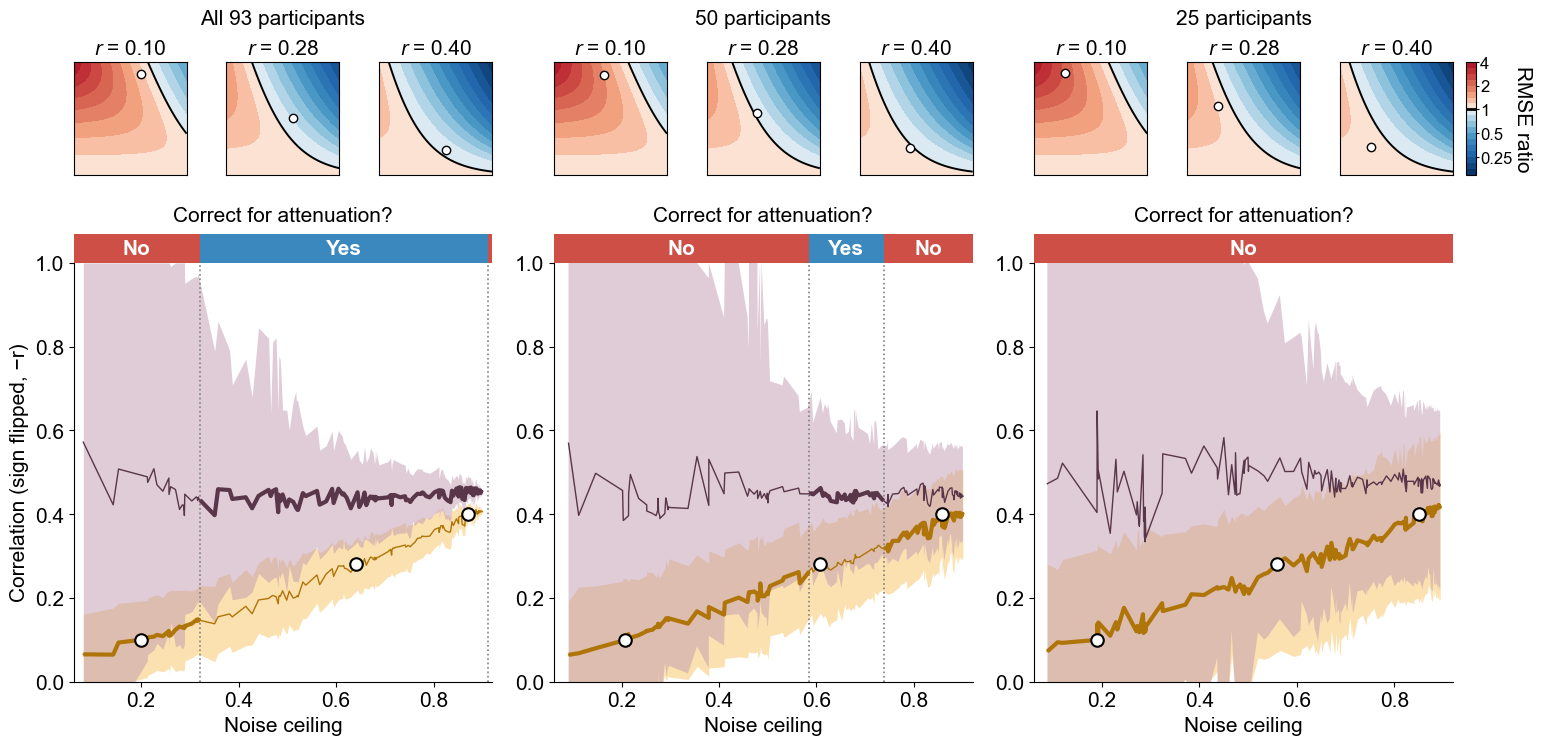

In [18]:
# crowding vs. RSVP correlation against the noise ceiling, for all, 50 and 25 participants (left to right).
# Above each panel: a Yes/No stripe (correct for attenuation?) with dotted vertical lines at the boundaries,
# and heatmaps of the RMSE ratio; the median line of the preferred estimator is in bold
# (corrected r where Yes, measured r where No)
panels = [(results, f'All {len(subjects)} participants', 'all')] + \
         [(results_subset[n], f'{n} participants', n) for n in sorted(subset_sizes, reverse=True)]
summaries = [summarize_draws(res) for res, _, _ in panels]
inset_points_per_panel = [inset_points(summary, inset_r) for summary in summaries]  # (noise ceilings, -r) per panel

# one color scale for every heatmap
z = [rmse_ratio_heatmap_data(r)[2] for _, rs in inset_points_per_panel for r in rs]
inset_colors = ratio_color_scale(min(float(v.min()) for v in z), max(float(v.max()) for v in z))

# colors of the stripe: the heatmaps' colors at RMSE ratio 1/stripe_ratio (blue) and stripe_ratio (red)
_, norm, cmap = inset_colors
stripe_colors = {'yes': cmap(norm(np.log2(1 / stripe_ratio))), 'no': cmap(norm(np.log2(stripe_ratio)))}

# ranges where r should not be corrected (closed-form rule), and where it should
no_correction = {key: closed_form_no_correction(summary, res['n_subjects'].iloc[0])[1]
                 for summary, (res, label, key) in zip(summaries, panels)}
correct = {key: complement_ranges(ranges) for key, ranges in no_correction.items()}

fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels) + 1, 7.5))
for ax, summary, (res, label, key) in zip(axes, summaries, panels):
    plot_corr_vs_ceiling_median(ax, summary, label)
    draw_preferred_lines(ax, summary, no_correction[key], correct[key])
axes[0].set_ylabel('Correlation (sign flipped, −r)')

# same x axis in every panel
x_min = min(ax.get_xlim()[0] for ax in axes)
x_max = max(ax.get_xlim()[1] for ax in axes)
for ax in axes:
    ax.set_xlim(x_min, x_max)

# Yes/No stripe and dotted boundaries, after the x limits are final
for ax, (res, label, key) in zip(axes, panels):
    draw_decision_stripe(ax, no_correction[key], correct[key], stripe_colors)
plt.tight_layout(rect=[0, 0, 0.93, 0.74])  # room above for the stripe and insets, and on the right for the colorbar

# insets go in after the layout is set, above the stripe
for ax, (ceilings, rs), (res, label, key) in zip(axes, inset_points_per_panel, panels):
    bounds = add_heatmap_insets(ax, res['n_subjects'].iloc[0], ceilings, rs, inset_colors, gap=inset_gap + stripe_height)
    ax.text(0.5, 1 + stripe_height + 0.02, 'Correct for attenuation?', transform=ax.transAxes, ha='center', va='bottom',
            fontsize=font_size)
    ax.set_title(label, y=bounds[0][1] + bounds[0][3] + panel_title_pad)

# colorbar beside the last heatmap, as tall as the heatmaps
x, y, width, height = bounds[-1]
cax = axes[-1].inset_axes([x + width + 0.03, y, 0.025, height])
add_ratio_colorbar(fig, cax, *inset_colors, fontsize=font_size, tick_fontsize=font_size*0.8)
save_figure(fig, 'corr_vs_noise_ceiling_v5')
plt.show()